# 8. The differentiable model (JAX)

`penicillium.jax_model` is the model's right-hand side as a JAX function: the same equations as the simulator,
jit-compiled and differentiable. Use it for linearisation (MPC, extended Kalman filters), parameter sensitivity and
gradients through integration.

**You need:** `pip install -e ".[jax]"`, and [diffrax](https://docs.kidger.site/diffrax/) for the last section.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

import jax
import jax.numpy as jnp

from penicillium import BatchParameters, Simulator, jax_model, model
from penicillium.simulator import DISTURBANCES

print(len(model.STATE_NAMES), "states:", model.STATE_NAMES[:12], "...")
print(len(model.PARAM_NAMES), "parameters and inputs:", model.PARAM_NAMES[:9], "...")

33 states: ('S', 'DO2', 'O2', 'P', 'V', 'Wt', 'pH', 'T', 'Q', 'Viscosity', 'Culture_age', 'a0') ...
31 parameters and inputs: ('mu_p', 'mux_max', 'alpha_kla', 'N_conc_paa', 'PAA_c', 'inhib_flag', 'Fs', 'Fg', 'RPM') ...


## An operating point from a simulated batch

The model takes the time `t` [h], the state `y` (laid out as `model.STATE_NAMES`, with pH as H⁺ concentration) and
`par` (laid out as `model.PARAM_NAMES`: kinetic parameters, inputs and disturbance values). This helper builds them
for sample `i` of a recorded batch, with the inputs applied during the next sample.

In [2]:
seed, i = 1, 600  # 120 h, in the production phase
res = Simulator().run(seed=seed)
bp = BatchParameters.from_seed(seed)


def operating_point(res, bp, i):
    y = []
    for name in model.STATE_NAMES[:31]:
        v = res[name][i]
        y.append(10**-v if name == "pH" else v * 1000 if name == "Q" else v)
    y += [0.0, 0.0]  # rate integrals restart every sample
    u = {
        name: res[name][i + 1]
        for name in ("Fs", "Fg", "RPM", "Fc", "Fh", "Fb", "Fa", "Fw", "pressure", "discharge", "Fpaa", "Foil")
    }
    par = [
        *bp.params,
        2,
        u["Fs"],
        u["Fg"],
        u["RPM"],
        u["Fc"],
        u["Fh"],
        u["Fb"],
        u["Fa"],
        0.2 / 20,
        u["Fw"],
        u["pressure"],
        4,
        u["discharge"],
        u["Fpaa"],
        u["Foil"],
        0,
        1,
        *(bp.disturbances[name][i + 1] for name in DISTURBANCES),
        0,
    ]
    return float(res.time[i]), np.array(y), np.array(par, dtype=float)


t, y, par = operating_point(res, bp, i)
dy = jax_model.rhs(t, y, par)
check = np.max(np.abs(np.asarray(dy) - np.array(model.rhs(t, y, par))) / (np.abs(dy) + 1e-12))
print(f"t = {t} h; JAX and NumPy right-hand sides agree to {check:.1e} (relative)")
print({name: round(float(v), 5) for name, v in zip(model.STATE_NAMES, dy) if name in ("S", "DO2", "P", "PAA", "T")})

t = 120.2 h; JAX and NumPy right-hand sides agree to 1.1e-12 (relative)
{'S': 0.0088, 'DO2': -1.22737, 'P': 0.13949, 'T': 0.16176, 'PAA': 14.67142}


## Exact Jacobians

`state_jacobian` gives ∂(dy/dt)/∂y (33 × 33) and `parameter_jacobian` gives ∂(dy/dt)/∂par (33 × 31), computed by
automatic differentiation rather than finite differences.

A: (33, 33), B: (33, 31); stiffness ratio ~1e+10 (fastest / slowest decay rate)


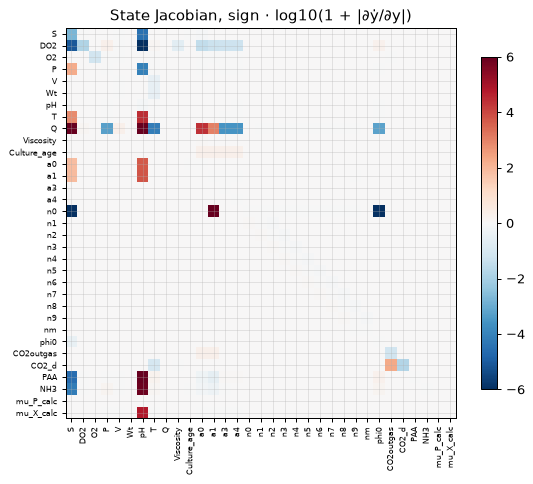

In [3]:
A = np.asarray(jax_model.state_jacobian(t, y, par))
B = np.asarray(jax_model.parameter_jacobian(t, y, par))

eig = np.linalg.eigvals(A)
fast, slow = np.abs(eig.real).max(), np.abs(eig.real[np.abs(eig.real) > 1e-9]).min()
print(f"A: {A.shape}, B: {B.shape}; stiffness ratio ~{fast / slow:.0e} (fastest / slowest decay rate)")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.sign(A) * np.log10(1 + np.abs(A)), cmap="RdBu_r", vmin=-6, vmax=6)
ax.set_xticks(range(33), model.STATE_NAMES, rotation=90, fontsize=6)
ax.set_yticks(range(33), model.STATE_NAMES, fontsize=6)
ax.set_title("State Jacobian, sign · log10(1 + |∂ẏ/∂y|)")
fig.colorbar(im, ax=ax, shrink=0.8);

### Sensitivity of the production rate

Row `P` of `B`, scaled to relative sensitivities: by what fraction the rate of change of penicillin moves for a
1 % change of each parameter or input.

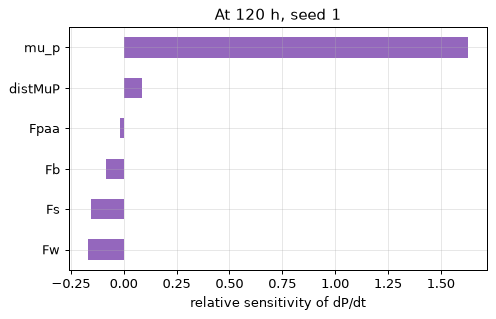

In [4]:
iP = model.STATE_NAMES.index("P")
rel = pd.Series(B[iP] * par / float(dy[iP]), index=model.PARAM_NAMES)
rel = rel[rel.abs() > 1e-3].sort_values()
ax = rel.plot.barh(figsize=(6, 3.5), color="tab:purple")
ax.set(xlabel="relative sensitivity of dP/dt", title="At 120 h, seed 1");

## Gradients through integration

With diffrax, a whole integration interval is differentiable. Here: how much penicillin there is after one
12-minute interval, and its gradient with respect to every parameter and input, checked against a finite
difference.

In [5]:
import diffrax


def penicillin_after(par, y0, t0=t, t1=t + 0.2):
    term = diffrax.ODETerm(lambda tt, yy, p: jax_model.rhs(tt, yy, p))
    sol = diffrax.diffeqsolve(
        term,
        diffrax.Kvaerno5(),
        t0,
        t1,
        0.001,
        y0,
        args=par,
        stepsize_controller=diffrax.PIDController(rtol=1e-8, atol=1e-10),
    )
    return sol.ys[-1][3]


p_end = penicillin_after(jnp.asarray(par), jnp.asarray(y))
grad = jax.grad(penicillin_after)(jnp.asarray(par), jnp.asarray(y))

k = model.PARAM_NAMES.index("Fs")
h = 1e-3 * par[k]
fd = (
    penicillin_after(jnp.asarray(par).at[k].add(h), jnp.asarray(y))
    - penicillin_after(jnp.asarray(par).at[k].add(-h), jnp.asarray(y))
) / (2 * h)
print(f"P after 0.2 h: {float(p_end):.4f} g/L")
print(f"dP/dFs: autodiff {float(grad[k]):.3e}, finite difference {float(fd):.3e} (g/L per L/h)")

P after 0.2 h: 19.5774 g/L
dP/dFs: autodiff 2.826e-04, finite difference 2.826e-04 (g/L per L/h)


The controllers and recipe events of a whole batch (`Simulator`) run in Python; to differentiate a complete batch,
write the control loop in JAX around `jax_model.rhs`. See [Differentiable model](../differentiable.md).

**Next:** [The command line](09_command_line.ipynb).